In [1]:
conda activate Pocket2mol


CondaError: Run 'conda init' before 'conda activate'


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os

# -- 1. 학습 설정 --
# configs/train.yml 파일을 사용합니다.
config_file = "./configs/train.yml"

# 학습 로그(logs)와 체크포인트(checkpoints)를 저장할 디렉토리입니다.
log_dir = "./logs"

# -- 2. 설정 파일 확인 --
if not os.path.exists(config_file):
    print(f"오류: '{config_file}'을 찾을 수 없습니다.")
    print("스크립트를 실행하기 전에 설정 파일의 경로를 확인하세요.")
else:
    print(f"'{config_file}' 설정을 사용하여 학습을 시작합니다.")
    print(f"로그는 '{log_dir}'에 저장됩니다.")
    
    # -- 3. 학습 명령어 실행 (Notebook에서 직접 실행) --
    # ! (느낌표)는 이 명령어를 터미널에서 실행하라는 의미입니다.
    !python train.py --config {config_file} --logdir {log_dir}

In [1]:
# --- [ 1. 설정 ] ---
# (필수) 'samples_all.pt'가 포함된 디렉토리 이름입니다.
EXP_NAME = "sample_0_2025_10_17__19_25_55" 

# (필수) EXP_NAME의 상위 디렉토리입니다.
RESULT_ROOT = "/home/nudge/Pocket2Mol/outputs" 

# (필수) PDB 파일들이 모여있는 경로
PROTEIN_ROOT = "/home/nudge/Pocket2Mol/evaluation/pdb_data" 

# (필수) 도킹에 사용할 Conda 환경 이름
DOCKING_ENV_NAME = "adt"

In [2]:
import os

# --- [수정] ---
# 'docking.py' 대신 'evaluation/docking.py' 경로를 사용합니다.
docking_file_path = 'evaluation/docking.py'

# docking.py 파일이 있는지 확인
if os.path.exists(docking_file_path):
    # Cell 1에서 정의한 DOCKING_ENV_NAME 변수('adt')를 사용합니다.
    # sed 명령어로 'pocket2mol_docking'을 'adt'로 변경합니다.
    !sed -i.bak "s/conda_env='pocket2mol_docking'/conda_env='{DOCKING_ENV_NAME}'/" {docking_file_path}
    
    print(f"--- '{docking_file_path}' 파일 패치 완료 ---")
    print(f"이제부터 {DOCKING_ENV_NAME} 환경을 사용합니다.")
else:
    print(f"오류: '{docking_file_path}' 파일이 없습니다.")
    print(f"현재 위치: {os.getcwd()}")

--- 'evaluation/docking.py' 파일 패치 완료 ---
이제부터 adt 환경을 사용합니다.


In [3]:
# [Jupyter Notebook 셀에서 실행]
import os
import sys
import torch
from tqdm.auto import tqdm
from rdkit.Chem.QED import qed
from rdkit import Chem

# 현재 폴더를 경로에 추가
sys.path.append('.')

try:
    from utils.reconstruct import reconstruct_from_generated_with_edges
    
    # --- [수정] evaluation.sascorer에서 calculateScore를 compute_sa_score로 임포트 ---
    from evaluation.sascorer import calculateScore as compute_sa_score
    
    from evaluation.docking import QVinaDockingTask
    from utils.misc import get_logger
    from evaluation.scoring_func import obey_lipinski, get_logp
    
    print("--- 모든 모듈 임포트 완료 ---")
    print("✅ SA Score 함수: calculateScore -> compute_sa_score로 매핑됨")
    
except ModuleNotFoundError as e:
    print(f"\n[오류] 모듈을 찾지 못했습니다: {e}")
    print("현재 작업 디렉토리:", os.getcwd())
    print("Python 경로:", sys.path)
except ImportError as e:
    print(f"\n[오류] 임포트 중 문제가 발생했습니다: {e}")

/home/nudge/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- 모든 모듈 임포트 완료 ---
✅ SA Score 함수: calculateScore -> compute_sa_score로 매핑됨


<frozen importlib._bootstrap>:488: RuntimeWarning: to-Python converter for boost::shared_ptr<RDKit::FilterHierarchyMatcher> already registered; second conversion method ignored.


In [4]:
# 셀 4

# --- [ 2. 경로 및 로거 설정 ] ---
# [Cell 1]에서 정의한 변수들을 사용합니다.
exp_dir = os.path.join(RESULT_ROOT, EXP_NAME)
sample_path = os.path.join(exp_dir, 'samples_all.pt')

# 로그 설정
logger = get_logger('evaluate_notebook', exp_dir)
logger.info(f"--- 평가 시작: {EXP_NAME} ---")
logger.info(f"샘플 파일 위치: {sample_path}")
logger.info(f"단백질 데이터 위치: {PROTEIN_ROOT}")
logger.info(f"도킹 환경: {DOCKING_ENV_NAME}")

# --- [ 3. 샘플 로드 ] ---
try:
    # --- [수정] ---
    # PyTorch 2.6+ 보안 정책 변경으로 인해 weights_only=False를 명시해야 합니다.
    # 이 파일은 신뢰할 수 있는 소스(본인 모델)에서 생성되었으므로 안전합니다.
    samples = torch.load(sample_path, map_location='cpu', weights_only=False) 
    
    logger.info(f"총 {len(samples.finished)}개의 완료된 샘플을 로드했습니다.")
    print(f"총 {len(samples.finished)}개의 샘플을 로드했습니다. 평가를 시작합니다...")
except FileNotFoundError:
    logger.error(f"파일을 찾을 수 없습니다: {sample_path}")
    print(f"오류: 샘플 파일({sample_path})을 찾을 수 없습니다. [Cell 1]의 EXP_NAME과 RESULT_ROOT를 확인하세요.")
    # 이 셀의 실행을 중단
    raise
except Exception as e:
    logger.error(f"샘플 로드 중 오류 발생: {e}")
    print(f"샘플 파일({sample_path})을 로드하는 중 오류가 발생했습니다: {e}")
    raise

# --- [ 4. 메인 루프 ] ---
results = []
failed_indices = []

# (선택) 테스트를 위해 샘플 수를 줄이려면 samples.finished[:10] 처럼 수정
for i, data in enumerate(tqdm(samples.finished, desc="분자 평가 중")):
    try:
        # 1. 분자 재구성
        mol = reconstruct_from_generated_with_edges(data)
        if mol is None:
            raise ValueError("분자 재구성 실패 (mol is None)")
        Chem.SanitizeMol(mol)

        # 2. 도킹 작업 생성 및 실행
        vina_task = QVinaDockingTask.from_generated_data(
            data, 
            protein_root=PROTEIN_ROOT
        )
        # run_sync()가 도킹을 실행하고 결과를 반환합니다.
        vina_results = vina_task.run_sync() 
        
        if not vina_results:
             raise ValueError("Vina 도킹 결과 없음")

        # 3. 화학적 속성 계산
        # [Cell 3]에서 임포트한 'compute_sa_score' (원래 'calculateScore') 사용
        sa_raw = compute_sa_score(mol)
        sa_norm = round((10 - sa_raw) / 9, 2) #

        results.append({
            'index': i,
            'mol': mol,
            'smiles': Chem.MolToSmiles(mol),
            'vina': vina_results, # Vina 결과 (리스트)
            'best_affinity': vina_results[0]['affinity'], # 가장 좋은 점수
            'qed': qed(mol),
            'sa': sa_norm,
            'lipinski': obey_lipinski(mol),
            'logp': get_logp(mol),
        })

    except Exception as e:
        logger.warning(f"샘플 {i} 처리 실패: {e}")
        failed_indices.append(i)

# --- [ 5. 결과 요약 ] ---
logger.info(f"--- 평가 완료 ---")
logger.info(f"총 {len(samples.finished)}개 중 {len(results)}개 성공, {len(failed_indices)}개 실패.")
print(f"\n평가 완료: {len(results)}개 성공 / {len(failed_indices)}개 실패")

if failed_indices:
    print(f"실패한 인덱스 (일부): {failed_indices[:20]}")
    print(f"자세한 내용은 '{exp_dir}/evaluate_notebook.log' 파일을 확인하세요.")

[2025-11-14 08:02:06,214::evaluate_notebook::INFO] --- 평가 시작: sample_0_2025_10_17__19_25_55 ---
[2025-11-14 08:02:06,214::evaluate_notebook::INFO] 샘플 파일 위치: /home/nudge/Pocket2Mol/outputs/sample_0_2025_10_17__19_25_55/samples_all.pt
[2025-11-14 08:02:06,214::evaluate_notebook::INFO] 단백질 데이터 위치: /home/nudge/Pocket2Mol/evaluation/pdb_data
[2025-11-14 08:02:06,215::evaluate_notebook::INFO] 도킹 환경: adt
[2025-11-14 08:02:06,996::evaluate_notebook::INFO] 총 121개의 완료된 샘플을 로드했습니다.


총 121개의 샘플을 로드했습니다. 평가를 시작합니다...


분자 평가 중:   1%|          | 1/121 [00:00<01:25,  1.40it/s]

Best affinity: -2.9


[08:02:08] DEPRECATION WARNING: please use MorganGenerator
분자 평가 중:   2%|▏         | 2/121 [00:01<01:08,  1.75it/s]

...

Best affinity: -6.4


[08:04:16] DEPRECATION WARNING: please use MorganGenerator
분자 평가 중:  99%|█████████▉| 120/121 [02:09<00:01,  1.13s/it]

Best affinity: -6.2


[08:04:18] DEPRECATION WARNING: please use MorganGenerator
분자 평가 중: 100%|██████████| 121/121 [02:11<00:00,  1.08s/it]
[2025-11-14 08:04:18,063::evaluate_notebook::INFO] --- 평가 완료 ---
[2025-11-14 08:04:18,064::evaluate_notebook::INFO] 총 121개 중 117개 성공, 4개 실패.


Best affinity: -6.0

평가 완료: 117개 성공 / 4개 실패
실패한 인덱스 (일부): [6, 16, 20, 60]
자세한 내용은 '/home/nudge/Pocket2Mol/outputs/sample_0_2025_10_17__19_25_55/evaluate_notebook.log' 파일을 확인하세요.


In [5]:
# --- [ 5. 결과 파일로 저장 ] ---
# [Cell 1]에서 설정한 exp_dir 경로를 사용합니다.
result_path = os.path.join(exp_dir, 'results_notebook.pt')
torch.save(results, result_path)

logger.info(f"최종 결과가 {result_path}에 저장되었습니다.")
print(f"최종 결과가 {result_path}에 저장되었습니다.")

[2025-11-14 08:05:53,096::evaluate_notebook::INFO] 최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_10_17__19_25_55/results_notebook.pt에 저장되었습니다.


최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_10_17__19_25_55/results_notebook.pt에 저장되었습니다.


--- 🔬 평가 결과 요약 (상위 5개) ---


,index,smiles,best_affinity,qed,sa,lipinski,logp
91,95,CC1=CC=c2cc3c(cc2N1)=CNC(N)=C3,-7.6,0.581795,0.64,5,0.3947
71,75,O=C(Oc1ccncc1)c1ccccc1,-7.2,0.696452,0.94,5,2.3008
103,107,NC1=Cc2cc3c(cc2=C(F)N1)NC=CC=3,-7.2,0.545575,0.64,5,0.3018
43,46,O=C1CNC=C(Cc2cccnc2)C1,-7.1,0.754482,0.76,5,1.0704
77,81,NC1=Cc2cc3c(cc2=CN1)NC=CC=3,-7.1,0.548678,0.64,5,0.0046



--- 📈 전체 성공 샘플 통계 (117개) ---


,best_affinity,qed,sa,lipinski,logp
count,117.000000,117.000000,117.000000,117.0,117.000000
mean,-6.227350,0.611136,0.752906,5.0,1.368552
std,0.733511,0.086317,0.100190,0.0,1.047920
min,-7.600000,0.384364,0.420000,5.0,-1.430500
25%,-6.700000,0.563404,0.670000,5.0,0.501800
50%,-6.400000,0.607090,0.770000,5.0,1.384800
75%,-6.000000,0.654737,0.830000,5.0,2.093720
max,-2.900000,0.819548,0.990000,5.0,4.032120



--- 💊 상위 5개 분자 구조 (결합력 좋은 순서) ---


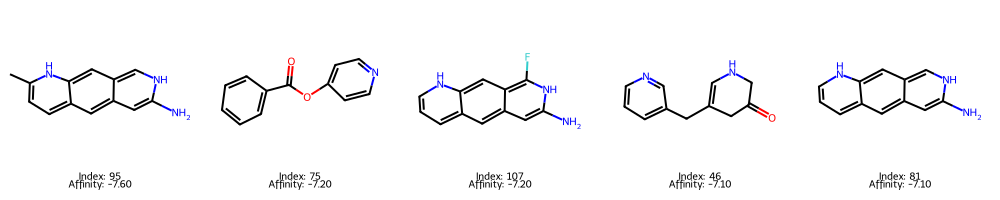

In [6]:
import pandas as pd
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole

# 'results' 변수가 메모리에 있고, 비어있지 않은지 확인
if 'results' in locals() and results:
    
    # --- 1. DataFrame 생성 ---
    # 'mol' (RDKit 객체)과 'vina' (전체 결과 리스트)는 너무 크므로 제외하고
    # 분석에 필요한 핵심 지표들로 DataFrame을 만듭니다.
    df_data = []
    for r in results:
        # [Cell 4]에서 저장한 모든 키 값을 포함
        df_data.append({
            'index': r.get('index'),
            'smiles': r.get('smiles'),
            'best_affinity': r.get('best_affinity'), # (Vina Affinity)
            'qed': r.get('qed'),                     # (QED)
            'sa': r.get('sa'),                       # (SA Score)
            'lipinski': r.get('lipinski'),           # (Lipinski)
            'logp': r.get('logp')                    # (LogP)
        })
    df = pd.DataFrame(df_data)
    
    # --- 2. 상위 5개 분자 선별 (결합력 기준) ---
    # 'best_affinity' (Vina 점수)가 낮은 순서(좋은 순서)대로 정렬
    df_sorted = df.sort_values(by='best_affinity', ascending=True)
    
    print("--- 🔬 평가 결과 요약 (상위 5개) ---")
    display(df_sorted.head())
    
    # --- 3. 전체 통계 요약 ---
    print("\n--- 📈 전체 성공 샘플 통계 (117개) ---")
    # 5가지 핵심 지표의 평균, 표준편차, 사분위수 등을 확인
    display(df[['best_affinity', 'qed', 'sa', 'lipinski', 'logp']].describe())
    
    # --- 4. 상위 5개 분자 구조 시각화 ---
    print("\n--- 💊 상위 5개 분자 구조 (결합력 좋은 순서) ---")
    
    # 정렬된 DataFrame에서 상위 5개의 'index'를 가져옴
    top_5_indices = df_sorted.head()['index'].tolist()
    
    # 'results' 리스트에서 'index'를 키로 mol 객체를 빠르게 찾기 위한 맵 생성
    mol_map = {r['index']: r['mol'] for r in results}
    legend_map = {r['index']: f"Index: {r['index']}\nAffinity: {r['best_affinity']:.2f}" for r in results}

    mols_to_draw = []
    legends = []
    
    # 정렬된 index 순서대로 mol 객체와 범례를 추가
    for idx in top_5_indices:
        if idx in mol_map:
            mols_to_draw.append(mol_map[idx])
            legends.append(legend_map[idx])

    # RDKit을 사용해 5개 분자 이미지를 그림
    img = Draw.MolsToGridImage(mols_to_draw, molsPerRow=5, subImgSize=(200, 200), legends=legends)
    display(img)
    
else:
    print("분석할 'results' 변수가 없습니다. [Cell 4]가 성공적으로 실행되었는지 확인하세요.")